# 10. Splines de Regressão e Splines de Suavização

## Objetivo

Avaliar a evolução temporal dos preços por tonelada das rotas comerciais brasileiras utilizando métodos de polinômios por partes e penalização de curvatura (Aula 10):

1. **Regression Splines (Spline Natural `ns()`):** Modelagem por pedaços fixando nós nos quantis dos dados e impondo comportamento linear nas extremidades para evitar oscilações fora dos limites;
2. **Smoothing Splines (`smooth.spline()`):** Alocação de nós em todos os pontos com controle de flexibilidade via penalização de curvatura ($\lambda$) otimizado por Validação Cruzada Generalizada (GCV).

## 0. Carregamento dos Scripts e Preparação do Ambiente


In [1]:
# Carrega o script de funções modulares
caminho_script <- file.path("..", "R", "analise_splines.R")
if (!file.exists(caminho_script)) {
  caminho_script <- file.path("estrutura", "R", "analise_splines.R")
}
source(caminho_script)

preparar_ambiente()
df_sazonal_lideres <- carregar_dados()
base_splines <- preparar_base_splines(df_sazonal_lideres)

cat(sprintf("Base preparada com sucesso: %d registros.\n", nrow(base_splines)))


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘scales’


The following object is masked from ‘package:readr’:

    col_factor



Attaching package: ‘purrr’


The following object is masked from ‘package:scales’:

    discard


ℹ Using "','" as decimal and "'.'" as grouping mark. Use `read_delim()` for more control.



Base preparada com sucesso: 481 registros.


## 1. Validação Cruzada (CV-5) em Regression Splines

Seleção dos graus de liberdade (df) ideais para a Spline Natural no tempo.

In [2]:
tabela_cv <- comparar_regression_splines(base_splines)
print(tabela_cv)

                                     modelo df rmse_cv
1     Baseline (Sem tempo): rota * log_peso NA 0.22571
2 Linear no tempo: rota * log_peso + rota:t  1 0.21682
3          Spline Natural no tempo (df = 3)  3 0.18713
4          Spline Natural no tempo (df = 4)  4 0.11083
5          Spline Natural no tempo (df = 5)  5 0.11268
6          Spline Natural no tempo (df = 6)  6 0.08713
7          Spline Natural no tempo (df = 8)  8 0.08439
8         Spline Natural no tempo (df = 10) 10 0.07917


## 2. Ajuste de Smoothing Splines via GCV

Ajuste da função `smooth.spline()` com seleção automática do parâmetro de suavização e graus de liberdade efetivos por rota.

In [3]:
res_smoothing <- ajustar_smoothing_splines_por_rota(base_splines)
print(res_smoothing)

           rota df_efetivo   lambda
1 Cubatão | Exp      43.80 0.000000
2 Guarujá | Exp      21.13 0.000006
3  Santos | Exp      25.12 0.000004
4 Cubatão | Imp      34.29 0.000001
5 Guarujá | Imp      32.66 0.000001
6  Santos | Imp      37.88 0.000001


## 3. Teste de Extrapolação (Treino no Passado x Teste no Futuro)

Avaliação do comportamento das splines ao prever pontos no limite e fora da janela de treino (demostrando o risco de extrapolação das splines).

In [4]:
res_futuro <- teste_futuro(base_splines, t_corte = 79)
print(res_futuro)

                   modelo n_teste rmse_futuro
1               Sem tempo      70      0.1537
2           Reta no tempo      70      0.2302
3 Spline Natural (df = 4)      70      0.1338
4 Spline Natural (df = 8)      70      0.2656


## 4. Visualização Comparativa dos Modelos

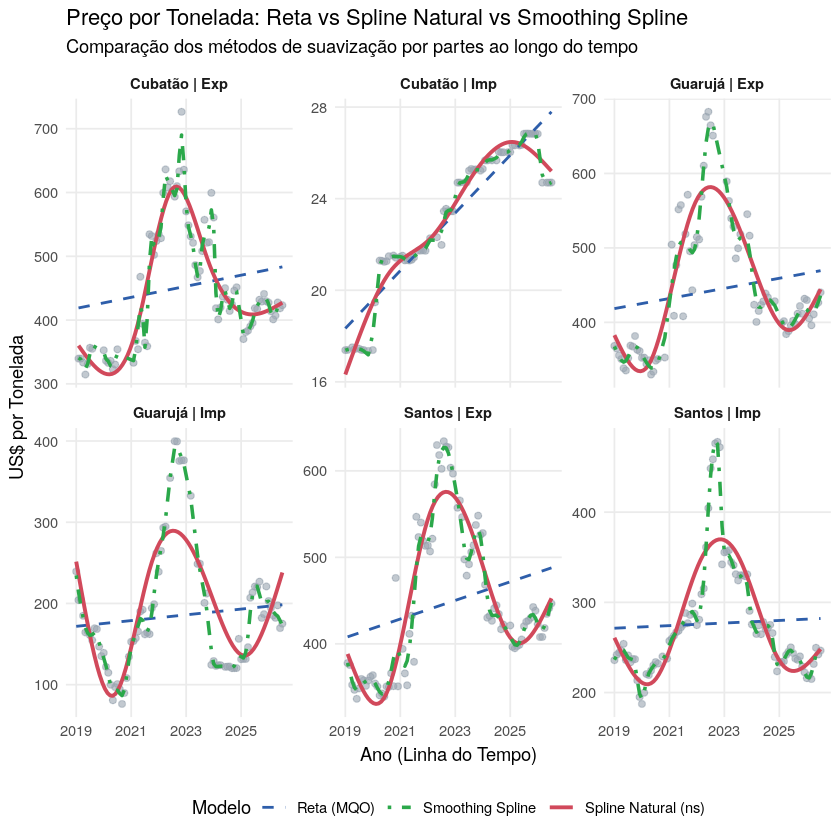

In [5]:
plotar_comparacao_splines(base_splines, df_ns = 5)